# Buscar perfiles más parecidos a los jugadores del club

## Librería

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

## Rutas y variables

In [7]:
# Rutas de Archivos
RUTA_DATA = Path.cwd().parent.parent / 'data'
RUTA_MERCADO = RUTA_DATA / 'scout' / 'mercado_viable_2627.csv'
RUTA_UDLP = RUTA_DATA / 'udlaspalmas' / 'Individual Las Palmas 2526.xlsx' # El dataset de Wyscout de la plantilla

# Diccionario
DICCIONARIO_COLUMNAS = {
    'Player': 'Jugador', 'Team': 'Equipo', 'Position': 'Posicion', 
    'Age': 'Edad', 'Foot': 'Pie', 'Pie': 'Pie',
    'Defensive duels per 90': 'Duelos_Defensivos_P90', 'Duelos defensivos/90': 'Duelos_Defensivos_P90',
    'Interceptions per 90': 'Interceptaciones_P90', 'Interceptaciones/90': 'Interceptaciones_P90',
    'Aerial duels per 90': 'Duelos_Aereos_P90', 'Duelos aéreos en los 90': 'Duelos_Aereos_P90',
    'Passes to final third per 90': 'Pases_Ultimo_Tercio_P90', 'Pases en el último tercio/90': 'Pases_Ultimo_Tercio_P90',
    'Progressive runs per 90': 'Conducciones_Progresivas_P90', 'Carreras en progresión/90': 'Conducciones_Progresivas_P90',
    'Key passes per 90': 'Pases_Clave_P90', 'Jugadas claves/90': 'Pases_Clave_P90',
    'Dribbles per 90': 'Regates_P90', 'Regates/90': 'Regates_P90',
    'Crosses per 90': 'Centros_P90', 'Centros/90': 'Centros_P90',
    'xA per 90': 'xA_P90', 'xA/90': 'xA_P90',
    'Goals per 90': 'Goles_P90', 'Goles/90': 'Goles_P90',
    'xG per 90': 'xG_P90', 'xG/90': 'xG_P90',
    'Touches in box per 90': 'Toques_Area_P90', 'Toques en el área de penalti/90': 'Toques_Area_P90',
    'Shots per 90': 'Remates_P90', 'Remates/90': 'Remates_P90',
    'Offensive duels per 90': 'Duelos_Ofensivos_P90', 'Duelos atacantes/90': 'Duelos_Ofensivos_P90'
}

# Vector de Comparación global
METRICAS_SIMILITUD = [
    'Duelos_Defensivos_P90', 'Interceptaciones_P90', 'Duelos_Aereos_P90',
    'Pases_Ultimo_Tercio_P90', 'Conducciones_Progresivas_P90', 'Pases_Clave_P90',
    'Regates_P90', 'Centros_P90', 'xA_P90', 'Goles_P90', 'xG_P90',
    'Toques_Area_P90', 'Remates_P90', 'Duelos_Ofensivos_P90'
]

## Similitud de jugadores

In [8]:
def normalizar_pie(pie):
    """Unifica la lateralidad sin importar si el Excel viene en inglés o español"""
    pie_str = str(pie).lower().strip()
    if pie_str in ['right', 'derecho']: return 'diestro'
    if pie_str in ['left', 'izquierdo']: return 'zurdo'
    if pie_str in ['both', 'ambidiestro']: return 'ambidiestro'
    return 'desconocido'

# Cargar la base de datos de mercado exportada previamente
df_mercado = pd.read_csv(RUTA_MERCADO).fillna(0)
df_mercado['Pie_Normalizado'] = df_mercado['Pie'].apply(normalizar_pie)

# Cargar y traducir los datos de Las Palmas
df_udlp = pd.read_excel(RUTA_UDLP).fillna(0)
df_udlp = df_udlp.rename(columns=DICCIONARIO_COLUMNAS)
df_udlp['Pie_Normalizado'] = df_udlp['Pie'].apply(normalizar_pie)

print(f"Bases de datos listas. Universo de mercado: {len(df_mercado)} jugadores.")

Bases de datos listas. Universo de mercado: 4653 jugadores.


In [16]:
def buscar_clon_estadistico(nombre_jugador, df_equipo, df_global, metricas, estricto_pie=True):
    """
    Busca al jugador más similar en la base de datos global utilizando Similitud del Coseno.
    """
    # Aislar al jugador objetivo (Target)
    target = df_equipo[df_equipo['Jugador'].str.contains(nombre_jugador, case=False, na=False)]
    if target.empty:
        print(f"Error: No se ha encontrado a '{nombre_jugador}' en la plantilla de la UDLP.")
        return pd.DataFrame()
    
    # Extraemos sus metadatos vitales
    target = target.iloc[0]
    posiciones_target = [p.strip() for p in target['Posicion'].split(',')] # Ej: ['LW', 'LAMF']
    posicion_principal = posiciones_target[0] # Cogemos su rol principal para buscar clones
    pie_target = target['Pie_Normalizado']
    
    print(f"Escaneando: {target['Jugador']}")
    print(f"Posición principal: {posicion_principal} | Pie Dominante: {pie_target.upper()}")
    
    # Filtrar el mercado por Posición y Pie
    mask_posicion = df_global['Posicion'].str.contains(posicion_principal, case=False, na=False)
    df_filtrado = df_global[mask_posicion].copy()
    
    if estricto_pie and pie_target != 'desconocido':
        df_filtrado = df_filtrado[df_filtrado['Pie_Normalizado'] == pie_target]
        
    if df_filtrado.empty:
        print("No hay jugadores en el mercado viable que cumplan la posición y el pie.")
        return pd.DataFrame()
        
    # Preparar vectores matemáticos para el algoritmo
    # Unimos al Target con el mercado para escalarlos en la misma dimensión
    df_modelo = pd.concat([pd.DataFrame([target]), df_filtrado]).reset_index(drop=True)
    
    # Validar que las métricas existen
    metricas_validas = [m for m in metricas if m in df_modelo.columns]
    X = df_modelo[metricas_validas].astype(float)
    
    # scalar los datos (Z-Score)
    # Fundamental: Evita que 'Pases' (valores de 40) aplaste a 'Goles' (valores de 0.2)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Calcular Similitud del Coseno
    # El target es el índice 0, comparamos el vector 0 contra todos los demás vectores
    vector_target = X_scaled[0].reshape(1, -1)
    similitudes = cosine_similarity(vector_target, X_scaled)[0]
    
    # Mapear resultados (Saltamos el índice 0 porque es el propio jugador)
    df_filtrado['Porcentaje_Clonacion'] = (similitudes[1:] * 100).round(2)
    
    # Formatear la salida ejecutiva
    cols_visuales = ['Jugador', 'Equipo', 'Edad', 'Valor_MEur', 'Fin_Contrato', 'Carpeta_Origen', 'Porcentaje_Clonacion']
    
    return df_filtrado.sort_values('Porcentaje_Clonacion', ascending=False)[cols_visuales].head(10).reset_index(drop=True)

In [19]:
# Escribe aquí el nombre del jugador de la plantilla 25/26 que quieras buscar (Mika Mármol, Kirian, Viti...)
JUGADOR_A_SUSTITUIR = "Mika Mármol" 

# Ejecutar Búsqueda (estricto_pie=True fuerza a que si Mika es zurdo, solo devuelva centrales zurdos)
clones = buscar_clon_estadistico(
    nombre_jugador=JUGADOR_A_SUSTITUIR, 
    df_equipo=df_udlp, 
    df_global=df_mercado, 
    metricas=METRICAS_SIMILITUD,
    estricto_pie=True 
)

if not clones.empty:
    print(f"\nTop 5 parecidos:")
    display(clones)

Escaneando: Mika Mármol
Posición principal: LCB | Pie Dominante: ZURDO

Top 5 parecidos:


,Jugador,Equipo,Edad,Valor_MEur,Fin_Contrato,Carpeta_Origen,Porcentaje_Clonacion
0,I. Mesík,Heracles,24.0,0.0,2028-06-30,ligas,66.14
1,G. Smal,Feyenoord,28.0,0.0,2028-06-30,ligas,61.93
2,A. García MacNulty,PEC Zwolle,23.0,0.0,2026-06-30,ligas,61.06
3,D. Janse,Groningen,20.0,0.0,2029-06-30,ligas,59.42
4,T. Quintero,Sparta Rotterdam,27.0,0.0,2027-06-30,ligas,57.01
5,J. Kramer,Go Ahead Eagles,29.0,0.0,2028-06-30,ligas,56.03
6,MT,Santa Clara,25.0,0.0,2028-06-30,ligas,52.43
7,Leonardo Lelo,Sporting Braga,26.0,0.0,2029-06-30,ligas,51.40
8,J. Hardeveld,Telstar,31.0,0.0,2027-06-30,ligas,48.99
9,Gonçalo Inácio,Sporting CP,24.0,0.0,2030-06-30,ligas,44.68


## Decisión final

Ranking fichajes:


,Jugador,Equipo,Valor_MEur,Score_Fit,Porcentaje_Clonacion,Score_Global
0,T. Quintero,Sparta Rotterdam,0.0,60.07,57.01,58.54


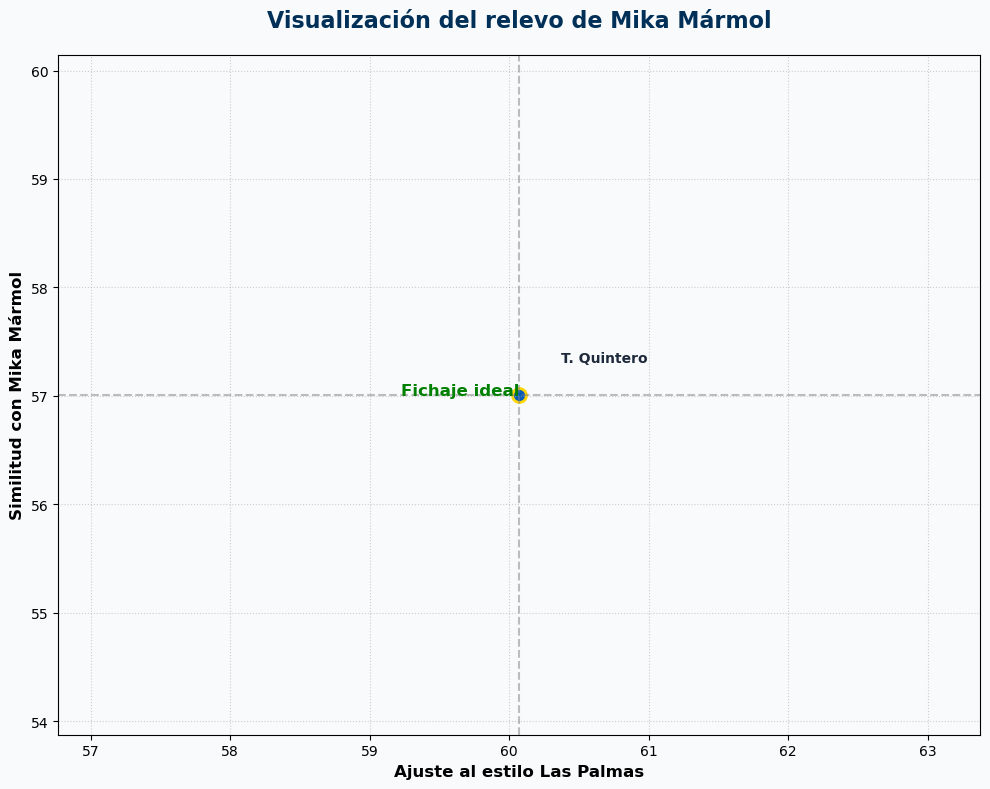

In [20]:
# Cargar el Top de Mercado (Score_Fit) que exportaste en mercado.ipynb
ruta_seleccion = Path.cwd().parent.parent / 'data' / 'seleccion' / 'top_opciones_mercado_2627.csv'
df_opciones_sistema = pd.read_csv(ruta_seleccion)

# Realizar copia del DF
df_clones = clones.copy()

# Fusionar algoritmos
df_decision = pd.merge(
    df_opciones_sistema[['Jugador', 'Equipo', 'Valor_MEur', 'Score_Fit']], 
    df_clones[['Jugador', 'Porcentaje_Clonacion']], 
    on='Jugador', 
    how='inner' 
)

# Cálculo de score
df_decision['Score_Global'] = ((df_decision['Score_Fit'] * 0.5) + (df_decision['Porcentaje_Clonacion'] * 0.5)).round(2)

# Ordenamos al ganador absoluto
df_decision = df_decision.sort_values('Score_Global', ascending=False).reset_index(drop=True)

print("Ranking fichajes:")
display(df_decision)

# Scatte plot
if not df_decision.empty:
    plt.figure(figsize=(10, 8), facecolor='#F8FAFC')
    ax = plt.gca()
    ax.set_facecolor('#F8FAFC')

    # Crear el gráfico de dispersión
    sns.scatterplot(
        data=df_decision, 
        x='Score_Fit', 
        y='Porcentaje_Clonacion', 
        size='Score_Global', 
        sizes=(100, 500), 
        color='#005BBB',
        edgecolor='#FFD700', 
        linewidth=2,
        legend=False
    )

    # Añadir líneas de media para crear los 4 cuadrantes
    media_fit = df_decision['Score_Fit'].mean()
    media_clon = df_decision['Porcentaje_Clonacion'].mean()
    plt.axvline(media_fit, color='gray', linestyle='--', alpha=0.5)
    plt.axhline(media_clon, color='gray', linestyle='--', alpha=0.5)

    # Añadir el nombre de cada jugador al lado de su burbuja
    for i, row in df_decision.iterrows():
        plt.text(row['Score_Fit'] + 0.3, row['Porcentaje_Clonacion'] + 0.3, 
                 row['Jugador'], fontsize=10, fontweight='bold', color='#1E293B')

    # Añadir etiquetas de los cuadrantes
    plt.text(df_decision['Score_Fit'].max(), df_decision['Porcentaje_Clonacion'].max(), 
             'Fichaje ideal', color='green', fontsize=12, fontweight='bold', ha='right')

    plt.title(f'Visualización del relevo de {JUGADOR_A_SUSTITUIR}', fontsize=16, fontweight='bold', color='#003057', pad=20)
    plt.xlabel('Ajuste al estilo Las Palmas', fontsize=12, fontweight='bold')
    plt.ylabel(f'Similitud con {JUGADOR_A_SUSTITUIR}', fontsize=12, fontweight='bold')
    
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()